In [1]:
from cfb.ml import *
from xgboost import XGBRegressor

In [2]:
def create_cfb_training_sets(df, features, target, training_range, validation_year, test_year):
    '''Creates Training, Validation, Testing Datasets'''
    train = df[df['season'].isin(training_range)]
    valid = df[df['season'] == validation_year]
    test = df[df['season'] == test_year]

    X_train, y_train = train[features], train[target]
    X_val, y_val = valid[features], valid[target]
    X_test, y_test = test[features], test[target]

    return X_train, y_train, X_val, y_val, X_test, y_test

# Punt Model

**Goal:** To create a model that can accurately predict the result of a punt. ie what the opponent's starting field position would be if a team decided to punt on fourth down

**Notes:** Using `marts.fourth_down_features` where decision = 'punt' and opponent starting yardage is >0 and <100

In [3]:
punt_query = '''
SELECT * 
FROM 
    marts.fourth_down_features 
WHERE
    decision = 'punt' 
    AND opp_start_ytg BETWEEN 1 AND 99
'''
punts = pd.read_sql(punt_query, engine)

In [4]:
punts.head()

,play_id,game_id,drive_id,season,week,offense,defense,decision,distance,yards_to_goal,...,off_elo,def_elo,elo_diff,offense_spread,fg_pct_szn,fg_att_szn,off_games_prior,opp_start_ytg,net_punt_yards,outcome
0,2123800380207,212380038,21238003802,2001,1,Fresno State,Colorado,punt,3,63,...,1573.0,1572.0,1.0,NaN,NaN,NaN,0.0,64,27,punt_returned
1,2123801831204,212380183,21238018312,2001,1,Syracuse,Georgia Tech,punt,3,74,...,1629.0,1711.0,-82.0,NaN,NaN,NaN,0.0,53,27,punt_returned
2,2124202181309,212420218,21242021813,2001,2,Navy,Temple,punt,4,39,...,1262.0,1408.0,-146.0,NaN,NaN,NaN,0.0,80,19,punt_touchback
3,2124226491007,212422649,21242264910,2001,2,Minnesota,Toledo,punt,13,72,...,1610.0,1723.0,-113.0,NaN,NaN,NaN,0.0,66,38,punt_returned
4,2124226492306,212422649,21242264923,2001,2,Minnesota,Toledo,punt,3,57,...,1610.0,1723.0,-113.0,NaN,NaN,NaN,0.0,92,49,punt_returned


In [5]:
# Target Variable Analysis
outcomes = punts.groupby('outcome').agg(
    avg_punt_yds=('net_punt_yards', 'mean'),
    avg_opp_start_yds=('opp_start_ytg', 'mean'),
    outcome_count=('outcome','count')   
)
outcomes['pct'] = (outcomes['outcome_count'] / sum(outcomes['outcome_count']))*100
print(outcomes)
print()
print(f"Target Skew: {punts['opp_start_ytg'].skew()}")
print()
print(punts['opp_start_ytg'].describe())

                avg_punt_yds  avg_opp_start_yds  outcome_count        pct
outcome                                                                  
punt_blocked        6.338961          38.087013            770   0.429338
punt_return_td     31.421687          64.951807             83   0.046279
punt_returned      37.910336          71.460855         161938  90.293622
punt_touchback     32.146602          80.000000          16555   9.230761

Target Skew: -0.8548967897482745

count    179346.000000
mean         72.102785
std          16.550587
min           1.000000
25%          62.000000
50%          75.000000
75%          84.000000
max          99.000000
Name: opp_start_ytg, dtype: float64


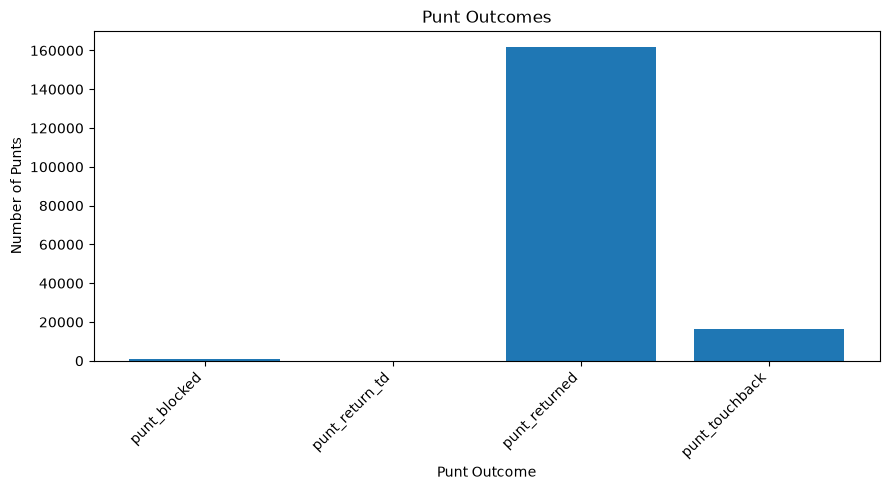

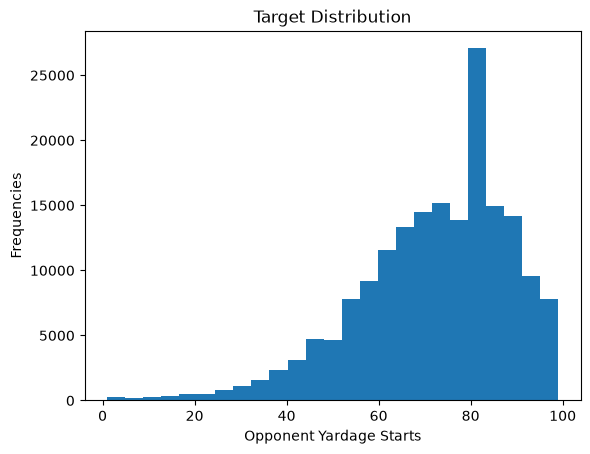

In [6]:
# Show Class Imbalance
plt.figure(figsize=(9, 5))
plt.bar(outcomes.index, outcomes['outcome_count'])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Punt Outcome')
plt.ylabel('Number of Punts')
plt.title('Punt Outcomes')
plt.tight_layout()
plt.show()

# Target Distribution
plt.hist(x=punts['opp_start_ytg'], bins=25)
plt.xlabel('Opponent Yardage Starts')
plt.ylabel('Frequencies')
plt.title("Target Distribution")
plt.show()

In [7]:
# Drop Identifiers and Targets
punts = punts.drop(columns=['play_id','game_id','drive_id','offense','defense','next_scoring_team',
                            'next_score_type','next_score_points','net_punt_yards','outcome','decision'],
                   errors='ignore')

punts['is_neutral'] = punts['is_neutral'].astype('bool')
numerical_columns = punts.select_dtypes(include='number').columns.to_list()
bool_columns = punts.select_dtypes(include=['bool']).columns.to_list()
punts[bool_columns] = punts[bool_columns].astype('float')

alternate_features = ['down','sec_left_in_half','yards_to_goal']

target = 'opp_start_ytg'
features = [c for c in punts.columns if c not in [target, 'season']]

numerical_features = [c for c in numerical_columns if c not in alternate_features + [target, 'season']]
bool_features = [c for c in bool_columns if c != target]

# Season Splits
training_years = range(2014, 2024)
validation_year = 2024
test_year = 2025

X_train, y_train, X_val, y_val, X_test, y_test = create_cfb_training_sets(
    punts, features, target, training_years, validation_year, test_year
)

# Check Shapes
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(79651, 22) (79651,)
(7610, 22) (7610,)
(7682, 22) (7682,)


In [8]:
# Scale training data for Neural Networks
preprocessor_with_indicators = make_pipeline(
    SimpleImputer(strategy='median', add_indicator=True),
    StandardScaler()
)

X_train_scaled = preprocessor_with_indicators.fit_transform(X_train).astype('float32')
X_val_scaled = preprocessor_with_indicators.transform(X_val).astype('float32')
X_test_scaled = preprocessor_with_indicators.transform(X_test).astype('float32')

num_features = X_train_scaled.shape[1]

In [9]:
# Baseline XGBoost Model
baseline_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=6,
    subsample=0.8,
    random_state=42,
    early_stopping_rounds=10
)

baseline_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# Evaluation
baseline_train_preds = baseline_model.predict(X_train)
baseline_val_preds = baseline_model.predict(X_val)

base_train_mae = mean_absolute_error(y_train, baseline_train_preds)
base_val_mae = mean_absolute_error(y_val, baseline_val_preds)

print(f"Training MAE    : {base_train_mae:2f}")
print(f"Validation MAE  : {base_val_mae:2f}")

# Add to Experiment Results for later
experiment_results = []

experiment_results.append({
    "Model" : "Baseline XGBoost",
    "Training MAE" : base_train_mae,
    "Validation MAE" : base_val_mae
})

Training MAE    : 8.023289
Validation MAE  : 8.038158


In [10]:
# Hyperparameter tuning via Grid search
params_grid = {
    'n_estimators'      : [250, 500, 1000],
    'max_depth'         : [3, 5, 7],
    'min_child_weight'  : [1, 10],          # XGBoost's version of min_samples_leaf
    'learning_rate'     : [0.03, 0.1]
}

# Train on 2014-2023, score on 2024 (instead of random folds that mix seasons)
X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])
season_split = PredefinedSplit(test_fold=[-1] * len(X_train) + [0] * len(X_val))

grid_search = GridSearchCV(
    estimator=XGBRegressor(subsample=0.8, random_state=42),
    param_grid=params_grid,
    scoring='neg_mean_absolute_error',
    cv=season_split,
    n_jobs=1,
    refit=False
)

grid_search.fit(X_search, y_search)

# Best Results
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"Best Params: {best_params}")
print(f"Best Score from Tuning: {best_score*-1}")

# Refit with Best Params
xgb2_model = XGBRegressor(**best_params, random_state=42, subsample=0.8)
xgb2_model.fit(X_train,y_train)

exp2_train_preds = xgb2_model.predict(X_train)
exp2_val_preds = xgb2_model.predict(X_val)

# Evaluate
xgb2_train_mae = mean_absolute_error(y_train, exp2_train_preds)
xgb2_val_mae = mean_absolute_error(y_val, exp2_val_preds)

print(f"Training MAE    : {xgb2_train_mae:2f}")
print(f"Validation MAE  : {xgb2_val_mae:2f}")

experiment_results.append({
    "Model" : "Tuned XGBoost",
    "Training MAE" : xgb2_train_mae,
    "Validation MAE" : xgb2_val_mae
})

Best Params: {'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 500}
Best Score from Tuning: 8.022665023803711
Training MAE    : 8.097874
Validation MAE  : 8.022665


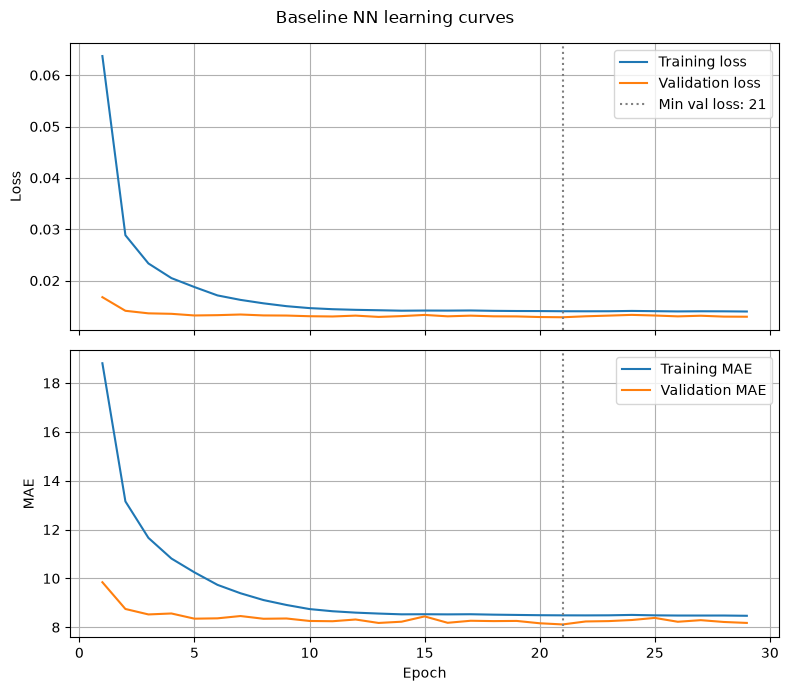

Training MAE    : 8.20
Validation MAE  : 8.11


In [11]:
# Baseline NN (PyTorch regression: predicts opponent's starting yards to goal)

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Target divided by 100 so the network's outputs stay in a small range (0.01 - 0.99)
X_tr = torch.tensor(X_train_scaled, dtype=torch.float32, device=device)
X_va = torch.tensor(X_val_scaled, dtype=torch.float32, device=device)
y_tr = torch.tensor(y_train.to_numpy(), dtype=torch.float32, device=device).view(-1, 1) / 100
y_va = torch.tensor(y_val.to_numpy(), dtype=torch.float32, device=device).view(-1, 1) / 100
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=256, shuffle=True)

baseline_nn = nn.Sequential(
    nn.Linear(num_features, 64), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(32, 1)                     # no activation: the output is the prediction itself
).to(device)

loss_fn = nn.MSELoss()                   # trains toward the average field position
optimizer = torch.optim.Adam(baseline_nn.parameters(), lr=0.001)


def predict_yards(model, X):
    """Predictions in yards (undo the / 100)."""
    model.eval()
    with torch.no_grad():
        return model(X).cpu().numpy().ravel() * 100


hist = {"loss": [], "val_loss": [], "mae": [], "val_mae": []}
best_loss, best_weights, patience, bad_epochs = float("inf"), None, 8, 0

for epoch in range(200):
    baseline_nn.train()
    total_loss, total_abs_err = 0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = baseline_nn(xb)
        loss = loss_fn(preds, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        total_abs_err += (preds - yb).abs().sum().item() * 100   # in yards
    hist["loss"].append(total_loss / len(X_tr))
    hist["mae"].append(total_abs_err / len(X_tr))

    baseline_nn.eval()
    with torch.no_grad():
        val_preds = baseline_nn(X_va)
        val_loss = loss_fn(val_preds, y_va).item()
        val_mae = (val_preds - y_va).abs().mean().item() * 100
    hist["val_loss"].append(val_loss)
    hist["val_mae"].append(val_mae)

    if val_loss < best_loss:
        best_loss, best_weights, bad_epochs = val_loss, copy.deepcopy(baseline_nn.state_dict()), 0
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            break

baseline_nn.load_state_dict(best_weights)

# Evaluation
plot_history(hist, title="Baseline NN learning curves", metric="mae")

nn_train_preds = predict_yards(baseline_nn, X_tr)
nn_val_preds = predict_yards(baseline_nn, X_va)

nn_train_mae = mean_absolute_error(y_train, nn_train_preds)
nn_val_mae = mean_absolute_error(y_val, nn_val_preds)

print(f"Training MAE    : {nn_train_mae:.2f}")
print(f"Validation MAE  : {nn_val_mae:.2f}")

experiment_results.append({
    "Model" : "Baseline NN (PyTorch)",
    "Training MAE" : nn_train_mae,
    "Validation MAE" : nn_val_mae
})


In [15]:
# Add in Naive model for comparison
naive_preds = np.full(len(y_val), y_train.median())
naive_val_mae = mean_absolute_error(y_val, naive_preds)

experiment_results.append({
    "Model"        : "Naive (training rate)",
    "Training MAE" : np.nan,
    "Validation MAE" : naive_val_mae
})

In [18]:
exp_results = pd.DataFrame(experiment_results)
exp_results.sort_values(by='Validation MAE', ascending=True)

,Model,Training MAE,Validation MAE
1,Tuned XGBoost,8.097874,8.022665
0,Baseline XGBoost,8.023289,8.038158
2,Baseline NN (PyTorch),8.203506,8.114892
3,Naive (training rate),NaN,12.495664


In [20]:
# Final Model
final_preds = xgb2_model.predict(X_test)
final_test_mae = mean_absolute_error(y_test, final_preds)

print(f"Final Test MAE: {final_test_mae}")

Final Test MAE: 8.188115119934082


In [ ]:
# Save the final model for the fourth-down decision tool
model_path = ROOT / 'models' / 'punt_model.joblib'
model_path.parent.mkdir(exist_ok=True)

joblib.dump({
    'model'    : xgb2_model,
    'features' : features,            # column order the model was trained on
}, model_path)

print(f"Saved: {model_path}")

# Conclusion

**1. Purpose**

The goal of this notebook is to create a model that could accurately predict the opposing team's field position given the decision to punt the ball away on fourth down


**2. Data**

Source: `marts.fourth_down_features`; Trained on 2014-2023 Seasons, Validated on 2024 Season, Tested on 2025 Season


**3. Results**

- Final Test MAE was about an 8 yard error from the actual position on the field
- Three models were traine. XGBoost models were trained because of their flexbility and it is the first time in the project that I needed a regressor rather than a classifier. Deep learning was attempted to try and learn PyTorch, but I knew that would probably be overkill for a problem like this and it likely wouldnt be the best performing model.
- Overall, an 8 yard MAE is not the best, but it makes sense given that variables like weather, bounce on impact, fair catch calls, etc could be used to affect the opponent's field position that cannot be picked up by the model. I am comfortable moving on knowing this.

**4. Limitations**

As previously stated, there are factors that wouldnt be known prior to prediction (like whether the opposing team would call a fair catch). And, things like weather (which I dont have access to) can play a big role in how punts go.

**5. Possible Improvements**

As always, player specific stats could play a role in this. Perhaps trying to find the opposing team's fair catch call percentage could also help.